# Which model explains a neuron's 2-object receptive field, per area? → `model_wins_and_probability_FEF.pdf`, `model_wins_and_probability_DMFC.pdf`

[`../figure_3/model_comparison/model_comparison.ipynb`](../figure_3/model_comparison/model_comparison.ipynb)'s
figure, drawn once over FEF neurons and once over DMFC neurons. One panel per monkey: of all (neuron, model) held-out accuracies at or above each threshold x, the fraction belonging to each model, with a bootstrap-SEM band over units; the inset counts the neurons each model is decisively called for.

This is the **sign-only** comparison: each model is scored on the orderings it predicts and on
nothing else — no confidence scale, no β, one parameter per model. See `comparison_lib`'s module
docstring for why.

Same fits, same neuron selection, same plotting code — only the population differs. **The knobs
below must match that notebook's**, or the supplement is not the same analysis split by area;
they are repeated here rather than imported because a figure should state the population it is
drawn over.


In [1]:
import matplotlib.pyplot as plt

import pandas as pd

import common
common.set_style()
import comparison_lib as cl
import stats_lib as sl

FIGSIZE = (4.9, 3.6)     # one row: tail fractions, with the counts as insets
OUTPUT = 'model_wins_and_probability_{area}.pdf'

# ── These must match ../figure_3/model_comparison/model_comparison.ipynb ──
# This supplement is the SIGN-ONLY model comparison: each model scored on the orderings it
# predicts and on nothing else — no confidence scale, no beta, one parameter per model. See
# that notebook, and `comparison_lib`'s module docstring, for why.
# The supplement is that figure split by area; if a knob here differs, the two are different
# analyses and the split no longer shows what it claims to.

# ── Style, copied from ../figure_3/model_comparison/model_comparison.ipynb ──────
# One row per subject: the tail-fraction curves, with the decisive counts as an inset.

# Tail-fraction panels. Of all (neuron, model) scores at or above each held-out-accuracy
# threshold, the fraction belonging to each model, with a bootstrap-SEM band.
#   min_tail     — curves stop where fewer than this many scores remain
#   n_boot, n_grid, seed — bootstrap replicates, thresholds on the x grid, RNG seed
#   sem_alpha    — opacity of the SEM band
TAIL_KW = dict(min_tail=10, n_boot=1000, n_grid=200, seed=0, sem_alpha=0.25)
N_XY = (0.66, 0.05)       # "N = ..." position, AXES FRACTIONS (bottom centre of the text) — figure 3's
# Fallbacks, tried in order per panel when N_XY would touch a curve, band or the inset; the first
# clear one is used. Figure 3's position stays wherever it is already clear.
N_XY_FALLBACKS = [(0.84, 0.05), (0.5, 0.05), (0.66, 0.14), (0.84, 0.14), (0.66, 0.24),
                  (0.84, 0.24), (0.84, 0.36)]
TITLE_PAD = 54            # points between the column titles and the axes; the legend sits there
LEGEND_DY_IN = 0.32       # INCHES to nudge the legend up (+) or down (−) from the axes' top
LEGEND_LW = 2           # line width (points) of the legend's markers; None = the curves' own (1.2)

# The count inset, in the panel's AXES FRACTIONS (0 = panel's left/bottom edge, 1 = its right/top).
INSET_X0 = 0.04           # left edge of the inset — raise to move it RIGHT
INSET_Y0 = 0.65           # bottom edge of the inset — raise to move it UP (its title sits above
                          # INSET_Y0 + INSET_HEIGHT, so it leaves the panel past ~0.97 total)
INSET_WIDTH = 0.47        # inset width
INSET_HEIGHT = 0.45       # inset height
# Room above the tallest bar for its count, as a multiple of that bar's height.
INSET_HEADROOM = 1.4
INSET_TITLE = '# Significant'
INSET_TITLE_PAD = -2.0     # points between the inset's top edge and its title; raise to lift it

# What the bar chart counts, matched to
# ../figure_3/model_comparison/model_comparison.ipynb.
#   'nearest'         — every neuron labelled by its highest held-out accuracy; nothing
#                       undecided.
#   'distinguishable' — the winner must beat BOTH other models on the comparisons where they
#                       predict different orderings, Holm-corrected over the two contrasts.
# Additionally require the winner to beat a constant model — which here is exactly chance, a
# neuron with no stimulus dependence being unable to order two trials at all.
DECISIVE_Q = 0.05      # threshold for the pairwise disagreement tests

# The shared population criterion (config.FDR_Q + config.MIN_DEV, via neuron_selection.py).
# On, as in the main text: these percentages are quoted against figure 3's.

In [2]:
raw = cl.load_units()
units = cl.add_decisive(
    sl.select_units(raw), q=DECISIVE_Q)
per_area = common.by_area(units)

2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 1339 -> 1339 neurons
FEF: 660 neurons (Monkey P 405, Monkey E 255)
DMFC: 679 neurons (Monkey P 593, Monkey E 86)


saved model_wins_and_probability_FEF.pdf


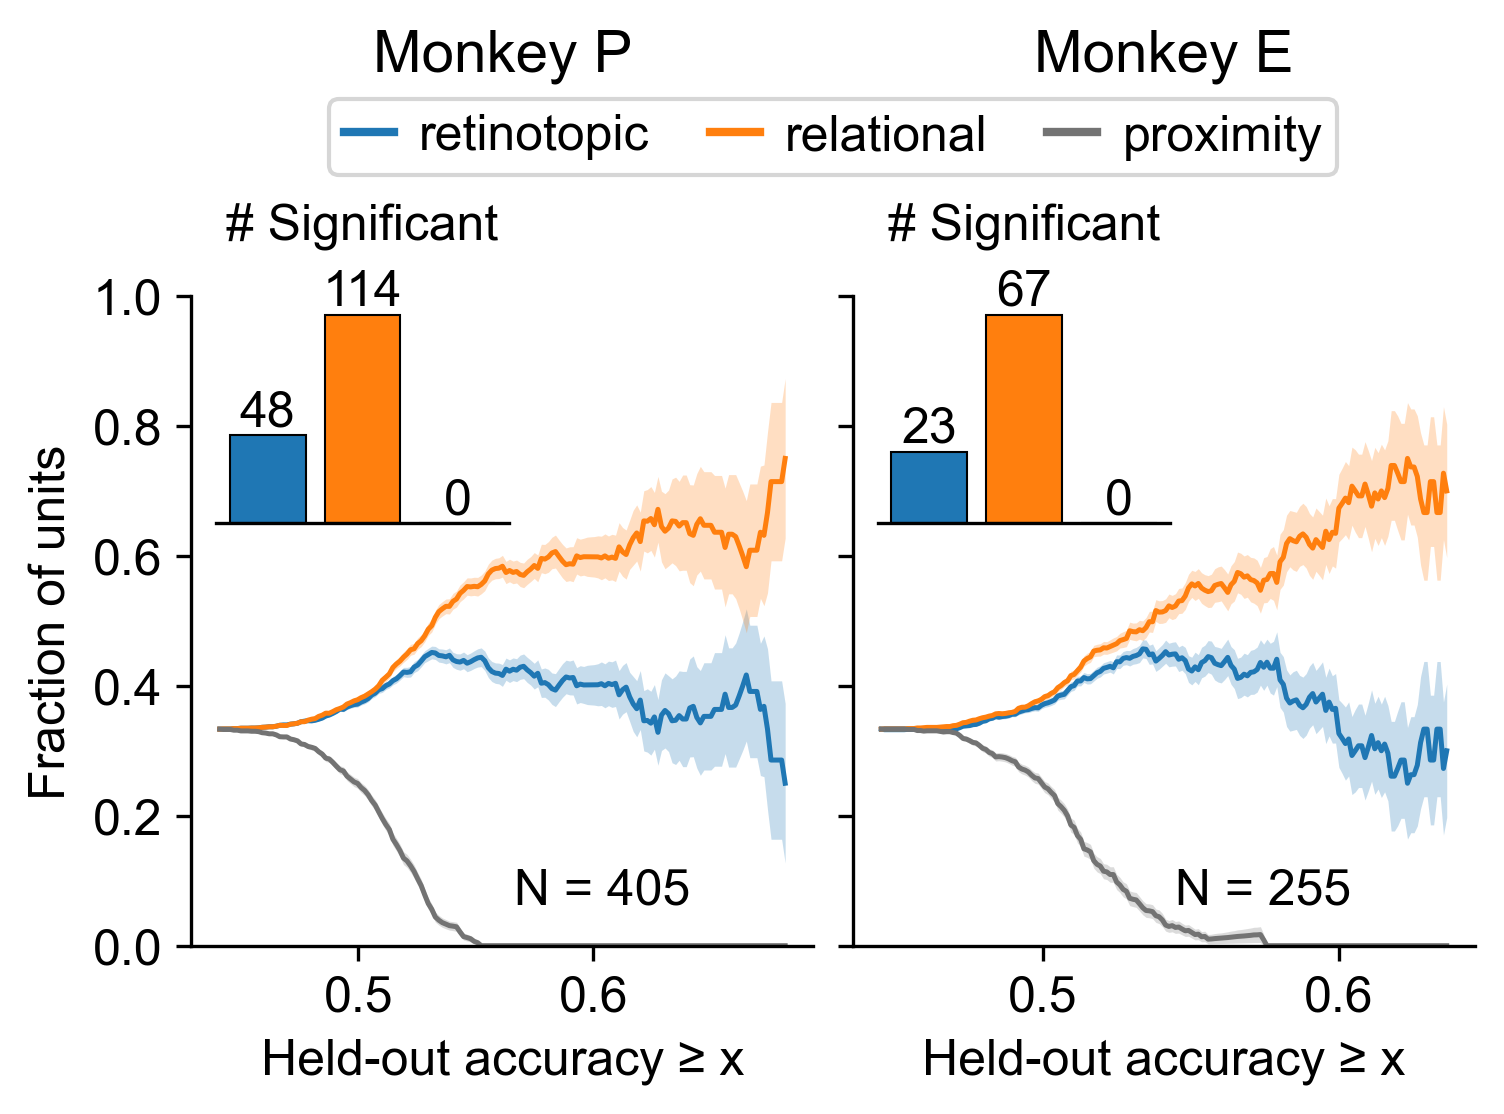

saved model_wins_and_probability_DMFC.pdf


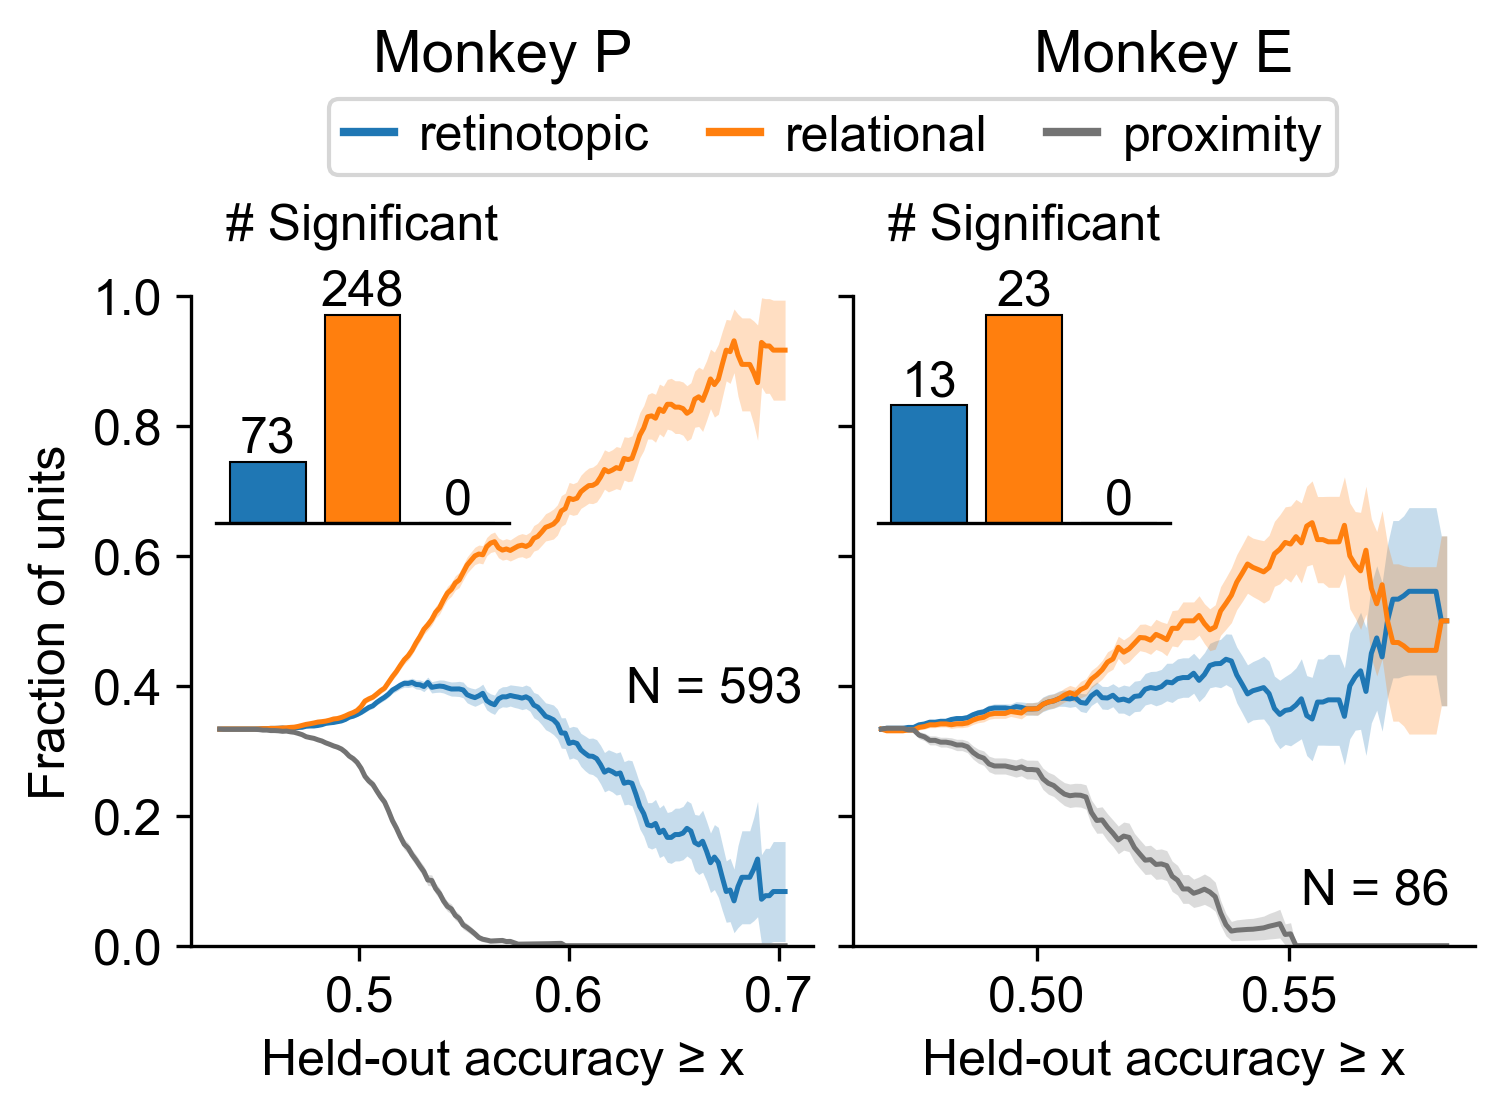

In [3]:
for area, area_units in per_area:
    fig = cl.plot_tail_with_count_insets(
        area_units, figsize=FIGSIZE, tail_kw=TAIL_KW,
        inset_bounds=(INSET_X0, INSET_Y0, INSET_WIDTH, INSET_HEIGHT),
        inset_headroom=INSET_HEADROOM, inset_title=INSET_TITLE,
        inset_title_pad=INSET_TITLE_PAD, n_xy=[N_XY] + N_XY_FALLBACKS, title_pad=TITLE_PAD,
        legend_dy_in=LEGEND_DY_IN,
        legend_lw=LEGEND_LW)
    common.save(fig, OUTPUT.format(area=area))
    plt.show()


## The relational share, area by area

The percentage of each (area, monkey) group whose winning model is relational — the top row
of each figure read as a share rather than a count, which is how the supplement quotes it.

In [4]:
for area, area_units in per_area:
    for subject in sl.ordered_subjects(area_units):
        g = area_units[area_units['subject'] == subject]
        called = g[g['decisive']]
        n_rel = int((called['best_model'] == 'relational').sum())
        # The share is of the CALLED neurons, which is what makes it comparable with figure
        # 3's percentages; the undecided count is printed beside it rather than folded in.
        print(f'{area:>4} {sl.subject_title(subject)}: '
              f'{100 * n_rel / max(len(called), 1):5.1f}% relational '
              f'({n_rel} of {len(called)} called, {len(g) - len(called)} undecided)')

 FEF Monkey P:  70.4% relational (114 of 162 called, 243 undecided)
 FEF Monkey E:  74.4% relational (67 of 90 called, 165 undecided)
DMFC Monkey P:  77.3% relational (248 of 321 called, 272 undecided)
DMFC Monkey E:  63.9% relational (23 of 36 called, 50 undecided)


## Where two models disagree, which one is right?

What is tabulated is the **disagreement test** the bar chart's `'distinguishable'` rule is built on. For each pair of
models, restrict to the held-out comparisons on which the two predict *different* orderings —
on exactly those, one model is right and the other wrong — and ask what fraction the first one
calls correctly.

`median_n` is how many such comparisons a neuron has, `median_prop_a` the fraction the first
model wins, `frac_a_favoured` the share of neurons above ½, and `frac_sig` the share at which
that departure from ½ is significant at `DECISIVE_Q` by the exact binomial test. The proportion,
not the p-value, is what a conclusion should rest on.


In [5]:
# Which model is right, where two of them disagree.
for area, area_units in per_area:
    print(f'── {area} ' + '─' * 56)
    rows = []
    for a, b in cl._PAIR_NAMES:
        for s_ in sl.ordered_subjects(area_units):
            g = area_units[area_units['subject'] == s_]
            rows.append(dict(subject=sl.subject_title(s_), pair=f'{a} vs {b}',
                             median_n=g[f'{a}_vs_{b}_n'].median(),
                             median_prop_a=g[f'{a}_vs_{b}_prop_a'].median(),
                             frac_a_favoured=(g[f'{a}_vs_{b}_prop_a'] > cl.CHANCE).mean(),
                             frac_sig=(g[f'{a}_vs_{b}_p'] < DECISIVE_Q).mean()))
    display(pd.DataFrame(rows).round(3))
    print()

── FEF ────────────────────────────────────────────────────────


,subject,pair,median_n,median_prop_a,frac_a_favoured,frac_sig
0,Monkey P,retinotopic vs relational,34488.0,0.488,0.400,0.447
1,Monkey E,retinotopic vs relational,25500.0,0.493,0.416,0.384
2,Monkey P,retinotopic vs proximity,33774.0,0.549,0.886,0.622
3,Monkey E,retinotopic vs proximity,25648.0,0.538,0.898,0.529
4,Monkey P,relational vs proximity,33865.0,0.558,0.938,0.731
5,Monkey E,relational vs proximity,24675.0,0.549,0.914,0.612



── DMFC ────────────────────────────────────────────────────────


,subject,pair,median_n,median_prop_a,frac_a_favoured,frac_sig
0,Monkey P,retinotopic vs relational,51303.0,0.475,0.327,0.600
1,Monkey E,retinotopic vs relational,92873.5,0.493,0.407,0.512
2,Monkey P,retinotopic vs proximity,51917.0,0.537,0.853,0.560
3,Monkey E,retinotopic vs proximity,92488.0,0.526,0.814,0.488
4,Monkey P,relational vs proximity,51925.0,0.562,0.921,0.744
5,Monkey E,relational vs proximity,89530.0,0.535,0.919,0.628
